# Building Custom Agentic Workflows with LangGraph: Routing Pattern

## Tutorial Overview

In this tutorial, you'll learn how to build a custom agentic workflow using **LangGraph** with intelligent routing capabilities. We'll create a system that:

- Analyzes user queries to detect intent
- Routes to appropriate processing paths based on the intent
- Executes either a web search (using Tavily) or direct LLM response
- Returns contextually appropriate results

## Learning Objectives

By the end of this tutorial, you will be able to:

1. Design and implement branching workflow patterns using LangGraph
2. Create conditional edges for intelligent routing
3. Implement intent detection for query classification
4. Integrate external tools (Tavily web search) into your workflow
5. Build modular, testable agentic systems

## Prerequisites

- Basic Python knowledge
- Understanding of LLMs and API calls
- API keys for:
  - OpenAI (or another LLM provider)
  - Tavily (for web search)

## What You'll Build

We'll build a **Smart Query Router** that:
- Receives a user question
- Detects if the question requires current/real-time information (web search) or can be answered directly
- Routes to the appropriate node
- Returns an augmented response

**Workflow Architecture:**

```
START → Intent Detection → [Conditional Edge] → Web Search Path OR Direct LLM Path → END
```

## Part 1: Environment Setup

First, let's install the required packages and load our environment variables.

In [33]:
# Install required packages
# Uncomment the following line if you need to install the packages
# !pip install langgraph langchain langchain-openai langchain-tavily python-dotenv

In [34]:
# Load environment variables
from dotenv import load_dotenv
import os

# Load API keys from .env file
load_dotenv()

# Verify that keys are loaded (don't print the actual keys!)
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in environment"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY not found in environment"

print("Environment variables loaded successfully!")

Environment variables loaded successfully!


## Part 2: Import Dependencies

Let's import all the libraries we'll need for building our workflow.

In [35]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_tavily import TavilySearch
from pydantic import BaseModel, Field
import json

print("All imports successful!")

All imports successful!


## Part 3: Define the State

In LangGraph, **state** is the data structure that flows through your workflow. Each node reads from and writes to this state.

For our routing workflow, we need to track:
- The user's query
- The detected intent
- Search results (if web search is used)
- The final response

In [36]:
class AgentState(TypedDict):
    """State schema for our agentic workflow."""
    
    # User's original query
    query: str
    
    # Detected intent: 'search' or 'direct'
    intent: str
    
    # Search results from Tavily (if applicable)
    search_results: str
    
    # Final response to return to user
    response: str

print("State schema defined!")
print("\nState fields:")
for field, field_type in AgentState.__annotations__.items():
    print(f"  - {field}: {field_type}")

State schema defined!

State fields:
  - query: <class 'str'>
  - intent: <class 'str'>
  - search_results: <class 'str'>
  - response: <class 'str'>


## Part 4: Initialize LLM and Tools

Let's set up our LLM (OpenAI), create a structured output model for intent detection, and initialize the Tavily search tool using the LangChain integration.

In [37]:
# Define Pydantic model for intent detection
class IntentClassification(BaseModel):
    """Schema for intent classification results."""
    
    intent: Literal["search", "direct"] = Field(
        description="The detected intent: 'search' for queries requiring current/real-time information, 'direct' for general knowledge questions"
    )
    reasoning: str = Field(
        description="Brief explanation of why this intent was chosen"
    )

# Initialize the language model
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Create structured output model for intent classification
intent_classifier = llm.with_structured_output(IntentClassification)

# Initialize Tavily search tool (using LangChain integration)
tavily_search = TavilySearch(max_results=3, topic="general")

print("LLM, intent classifier, and Tavily search tool initialized!")
print("\nIntent Classification Schema:")
print(f"  - intent: Literal['search', 'direct']")
print(f"  - reasoning: str")

LLM, intent classifier, and Tavily search tool initialized!

Intent Classification Schema:
  - intent: Literal['search', 'direct']
  - reasoning: str


## Part 5: Build the Nodes

Nodes are the processing units in your workflow. Each node is a function that:
1. Receives the current state
2. Performs some processing
3. Returns updates to the state

We'll create three nodes:
1. **Intent Detection Node**: Analyzes the query to determine if web search is needed
2. **Web Search Node**: Performs web search and augments response with current information
3. **Direct Response Node**: Generates response directly from LLM knowledge

### Node 1: Intent Detection

This node analyzes the user's query and classifies it as either:
- **search**: Requires current/real-time information (weather, news, stock prices, etc.)
- **direct**: Can be answered from LLM's training knowledge (definitions, general facts, coding help, etc.)

We use **structured output with Pydantic** to ensure reliable, type-safe intent classification.

In [38]:
def intent_detection_node(state: AgentState) -> AgentState:
    """
    Analyzes the user query and determines the appropriate processing path using structured output.
    
    Returns:
        Updated state with 'intent' field set to either 'search' or 'direct'
    """
    query = state["query"]
    
    # Create a prompt for intent classification
    system_prompt = """You are an intent classifier for a query routing system.

Analyze the user's query and determine if it requires:
- SEARCH: Current/real-time information (news, weather, stock prices, recent events, current facts)
- DIRECT: General knowledge, definitions, explanations, coding help, historical facts

Provide your classification with reasoning.

Examples:
- "What's the weather in Paris today?" -> search (requires current data)
- "Explain how neural networks work" -> direct (general knowledge)
- "Latest news about AI" -> search (requires current information)
- "How do I write a for loop in Python?" -> direct (coding help from training)
"""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": f"Query: {query}"}
    ]
    
    # Use structured output to get intent classification
    result = intent_classifier.invoke(messages)
    
    print(f"Intent detected: {result.intent}")
    print(f"Reasoning: {result.reasoning}")
    
    return {**state, "intent": result.intent}

print("Intent detection node created with structured output!")

Intent detection node created with structured output!


### Node 2: Web Search Path

This node:
1. Uses Tavily (via LangChain integration) to search the web for current information
2. Extracts relevant results
3. Uses the LLM to generate a response augmented with search results

In [39]:
def web_search_node(state: AgentState) -> AgentState:
    """
    Performs web search using Tavily (LangChain integration) and generates an augmented response.
    
    Returns:
        Updated state with 'search_results' and 'response' fields populated
    """
    query = state["query"]
    
    print(f"Performing web search for: {query}")
    
    # Perform the web search using LangChain Tavily tool
    # The tool returns a dictionary with 'results', 'answer', 'query', etc.
    search_response = tavily_search.invoke({"query": query})
    
    # Extract the results list from the response
    search_results = search_response.get("results", [])
    
    print(f"Found {len(search_results)} search results")
    
    # Format search results for the LLM
    formatted_results = "\n\n".join([
        f"Title: {r.get('title', 'N/A')}\nURL: {r.get('url', 'N/A')}\nContent: {r.get('content', '')}"
        for r in search_results
    ])
    
    # Generate response using search results
    system_prompt = """You are a helpful assistant that answers questions using web search results.
    
Use the provided search results to give an accurate, informative answer.
Always cite your sources by mentioning the titles and URLs.
If the search results don't contain relevant information, say so.
"""
    
    user_prompt = f"""Question: {query}

Search Results:
{formatted_results}

Please provide a clear, concise answer based on these search results."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ]
    
    response = llm.invoke(messages)
    
    return {
        **state,
        "search_results": formatted_results,
        "response": response.content
    }

print("Web search node created!")

Web search node created!


### Node 3: Direct Response Path

This node generates a response directly from the LLM's training knowledge, without web search.

In [40]:
def direct_response_node(state: AgentState) -> AgentState:
    """
    Generates a direct response using the LLM's knowledge.
    
    Returns:
        Updated state with 'response' field populated
    """
    query = state["query"]
    
    print(f"Generating direct response for: {query}")
    
    system_prompt = """You are a helpful assistant that provides clear, accurate answers.
    
Answer questions using your knowledge and training.
Be concise but thorough.
If you're not certain about something, acknowledge the uncertainty.
"""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=query)
    ]
    
    response = llm.invoke(messages)
    
    return {**state, "response": response.content}

print("Direct response node created!")

Direct response node created!


## Part 6: Create the Router Function

The router function is used with **conditional edges** in LangGraph. It examines the state and returns the name of the next node to execute.

This is the key to branching workflows!

In [41]:
def route_by_intent(state: AgentState) -> Literal["web_search", "direct_response"]:
    """
    Routes to the appropriate processing node based on detected intent.
    
    Args:
        state: Current agent state containing the 'intent' field
    
    Returns:
        Name of the next node to execute: 'web_search' or 'direct_response'
    """
    intent = state["intent"]
    
    if intent == "search":
        print("Routing to: web_search node")
        return "web_search"
    else:
        print("Routing to: direct_response node")
        return "direct_response"

print("Router function created!")

Router function created!


## Part 7: Build the Graph

Now we'll assemble everything into a LangGraph workflow:

1. Create a `StateGraph` with our state schema
2. Add all nodes
3. Connect nodes with edges:
   - Regular edges for fixed transitions
   - Conditional edges for dynamic routing
4. Compile the graph into an executable app

In [42]:
# Create the state graph
workflow = StateGraph(AgentState)

# Add nodes to the graph
workflow.add_node("intent_detection", intent_detection_node)
workflow.add_node("web_search", web_search_node)
workflow.add_node("direct_response", direct_response_node)

# Add edges
# 1. Start with intent detection
workflow.add_edge(START, "intent_detection")

# 2. Use conditional edge to route based on intent
workflow.add_conditional_edges(
    "intent_detection",  # Source node
    route_by_intent,     # Router function
    {
        "web_search": "web_search",           # If router returns 'web_search'
        "direct_response": "direct_response"  # If router returns 'direct_response'
    }
)

# 3. Both paths end after execution
workflow.add_edge("web_search", END)
workflow.add_edge("direct_response", END)

# Compile the graph into an executable app
app = workflow.compile()

print("Graph compiled successfully!")
print("\nWorkflow structure:")
print("  START → intent_detection → [conditional routing]")
print("                              ├─→ web_search → END")
print("                              └─→ direct_response → END")

Graph compiled successfully!

Workflow structure:
  START → intent_detection → [conditional routing]
                              ├─→ web_search → END
                              └─→ direct_response → END


## Part 8: Visualize the Graph (Optional)

LangGraph provides built-in visualization capabilities. Let's visualize our workflow!

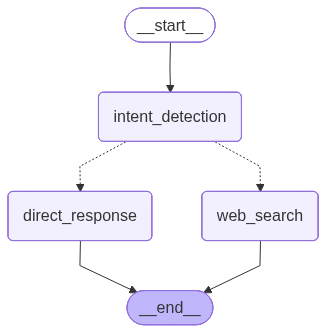

In [43]:
# Try to visualize the graph
try:
    from IPython.display import Image, display
    
    # Generate and display the graph visualization
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Visualization not available: {e}")
    print("\nGraph structure (text representation):")
    print(app.get_graph().to_json())

## Part 9: Test the Workflow

Let's test our workflow with different types of queries to see the routing in action!

### Test 1: Query Requiring Web Search

This query asks about current information, so it should route to the web search node.

In [44]:
# Test with a query that requires web search
test_query_1 = "What are the latest developments in AI safety research?"

print(f"Testing Query 1: {test_query_1}")
print("=" * 80)

# Create initial state
initial_state = {
    "query": test_query_1,
    "intent": "",
    "search_results": "",
    "response": ""
}

# Run the workflow
result = app.invoke(initial_state)

# Display results
print("\n" + "=" * 80)
print("FINAL RESULT")
print("=" * 80)
print(f"\nIntent: {result['intent']}")
print(f"\nResponse:\n{result['response']}")

Testing Query 1: What are the latest developments in AI safety research?
Intent detected: search
Reasoning: The query asks for the latest developments, which implies a need for current and real-time information about AI safety research.
Routing to: web_search node
Performing web search for: What are the latest developments in AI safety research?
Found 3 search results

FINAL RESULT

Intent: search

Response:
Recent developments in AI safety research indicate a significant increase in activity and focus in this field. Notably, AI safety research has grown by 312% from 2018 to 2023, reflecting a substantial uptick in interest and investment compared to previous years. This growth suggests a heightened awareness of the potential risks associated with AI technologies and the need for effective safety measures.

For ongoing updates and analysis, resources like the AI Safety Newsletter provide insights into the latest research, policy changes, and industry news related to AI safety. Addition

### Test 2: Query for Direct Response

This query asks about general knowledge, so it should route to the direct response node.

In [45]:
# Test with a query that can be answered directly
test_query_2 = "Explain the difference between supervised and unsupervised learning"

print(f"Testing Query 2: {test_query_2}")
print("=" * 80)

# Create initial state
initial_state = {
    "query": test_query_2,
    "intent": "",
    "search_results": "",
    "response": ""
}

# Run the workflow
result = app.invoke(initial_state)

# Display results
print("\n" + "=" * 80)
print("FINAL RESULT")
print("=" * 80)
print(f"\nIntent: {result['intent']}")
print(f"\nResponse:\n{result['response']}")

Testing Query 2: Explain the difference between supervised and unsupervised learning
Intent detected: direct
Reasoning: The query asks for a general explanation of concepts in machine learning, which falls under general knowledge.
Routing to: direct_response node
Generating direct response for: Explain the difference between supervised and unsupervised learning

FINAL RESULT

Intent: direct

Response:
Supervised and unsupervised learning are two main types of machine learning techniques, each with distinct characteristics and applications.

### Supervised Learning:
- **Definition**: In supervised learning, the model is trained on a labeled dataset, which means that each training example is paired with an output label or target value.
- **Goal**: The goal is to learn a mapping from inputs to outputs so that the model can predict the output for new, unseen data.
- **Examples**: Common tasks include classification (e.g., spam detection, image recognition) and regression (e.g., predicting 